# Импорты и настройки

In [9]:
# Основные библиотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi

# Загрузка данных
from ucimlrepo import fetch_ucirepo 

# Превью DF

In [10]:
bank_marketing = fetch_ucirepo(id=222)

X = bank_marketing.data.features
y = bank_marketing.data.targets

df = pd.concat([X, y], axis=1)

df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     8252 non-null   object
 16  y            45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


**Задача:** предсказать, оформит ли клиент срочный депозит после телефонного маркетингового звонка (`y`).
**Данные:** ~ 45000 наблюдений, 16 признаков

In [11]:
import matplotlib.ticker as mticker

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 4.2)

TARGET = "y"
BASE_RATE = df[TARGET].eq("yes").mean()
NUM_COLS = ["age", "balance", "duration", "campaign", "previous", "pdays"]
CAT_COLS = ["job", "marital", "education", "default", "housing", "loan", "contact", "poutcome", "month"]
NUMERIC_COLS = ["age", "balance", "duration", "campaign", "previous"]
RANDOM_STATE = 42

## 1. Общий обзор

In [12]:
overview = pd.DataFrame({
    "тип": df.dtypes.astype(str),
    "уникальных": df.nunique(),
    "пропусков": df.isna().sum(),
    "пример значения": df.iloc[0].astype(str),
})
print(f"Строк: {df.shape[0]:,} | столбцов: {df.shape[1]}")
print(f"Объём в памяти: {df.memory_usage(deep=True).sum() / 1024**2:.1f} МБ")
overview

Строк: 45,211 | столбцов: 17
Объём в памяти: 24.6 МБ


,тип,уникальных,пропусков,пример значения
age,int64,77,0,58
job,object,11,288,management
marital,object,3,0,married
education,object,3,1857,tertiary
default,object,2,0,no
balance,int64,7168,0,2143
housing,object,2,0,yes
loan,object,2,0,no
contact,object,2,13020,nan
day_of_week,int64,31,0,5


In [13]:
df.sample(8, random_state=RANDOM_STATE)

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
3776,40,blue-collar,married,secondary,no,580,yes,no,NaN,16,may,192,1,-1,0,NaN,no
9928,47,services,single,secondary,no,3644,no,no,NaN,9,jun,83,2,-1,0,NaN,no
33409,25,student,single,tertiary,no,538,yes,no,cellular,20,apr,226,1,-1,0,NaN,no
31885,42,management,married,tertiary,no,1773,no,no,cellular,9,apr,311,1,336,1,failure,no
15738,56,management,married,tertiary,no,217,no,yes,cellular,21,jul,121,2,-1,0,NaN,no
30813,28,blue-collar,married,secondary,no,1134,no,no,cellular,9,feb,130,3,-1,0,NaN,no
35463,24,management,single,tertiary,no,1085,no,yes,cellular,7,may,95,6,-1,0,NaN,no
31382,37,admin.,single,secondary,no,127,no,no,cellular,23,mar,83,4,-1,0,NaN,no


## 2. Качество данных

In [14]:
quality = pd.DataFrame({
    "пропущено": df.isna().sum(),
    "доля пропусков, %": (df.isna().mean() * 100).round(2),
    "уникальных": df.nunique(),
})
quality[quality["пропущено"] > 0].sort_values("пропущено", ascending=False)

,пропущено,"доля пропусков, %",уникальных
poutcome,36959,81.75,3
contact,13020,28.80,2
education,1857,4.11,3
job,288,0.64,11


In [15]:
# смотрим, что pdays и poutcome означают отсутствие прошлых контактов
print("pdays = -1 эквивалентно previous = 0:", bool(df.pdays.eq(-1).eq(df.previous.eq(0)).all()))
pd.crosstab(df.poutcome.isna().rename("poutcome пусто"),
            df.previous.gt(0).rename("контакты до кампании были"))

pdays = -1 эквивалентно previous = 0: True


контакты до кампании были,False,True
poutcome пусто,,
False,0,8252
True,36954,5


Пропуски в датасете это не дыры, а замаскированные unknown из исходника. poutcome пустой ровно у тех, кого раньше не контактировали (previous == 0, расхождение всего в 5 строках), а contact неизвестен у 28.8% клиентов, и конверсия у них 4.1% против 11.7% в среднем. Оба пропуска что-то значат, поэтому их лучше выносить в отдельную категорию unknown, а не заполнять модой.

pdays == -1 и previous == 0 это один и тот же факт (36954 строки, 81.7%), просто записанный дважды.

Ещё day_of_week на самом деле хранит день месяца (1..31), а не день недели, название столбца вводит в заблуждение.

Полных дублей строк нет, в остальных столбцах пропусков тоже нет, education (4.1%) и job (0.6%) это те же unknown.

Так что NaN в категориальных пойдут отдельной категорией, а из pdays сделаю флаг "был контакт" плюс само значение для тех, у кого он был.

## 3. Целевая переменная

y
no     39922
yes     5289

Доля откликов: 11.70% — дисбаланс классов 7.5 : 1


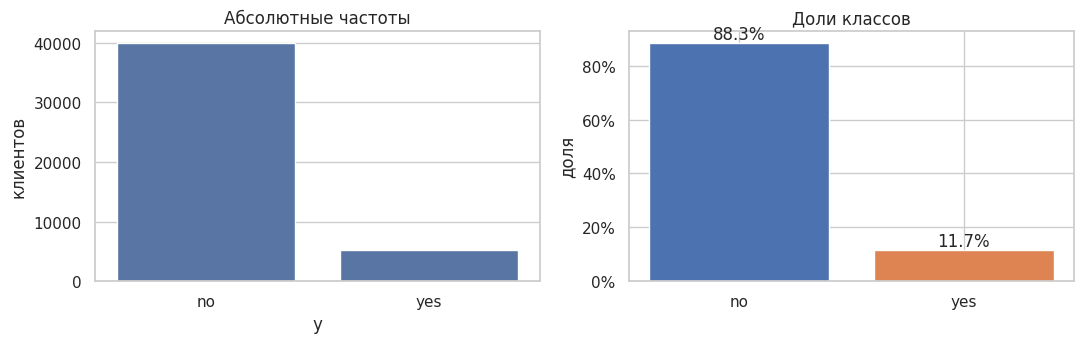

In [16]:
target_counts = df[TARGET].value_counts()
share = target_counts / len(df)
print(target_counts.to_string())
print(f"\nДоля откликов: {BASE_RATE:.2%} — дисбаланс классов {target_counts['no'] / target_counts['yes']:.1f} : 1")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.countplot(data=df, x=TARGET, ax=axes[0])
axes[0].set_title("Абсолютные частоты")
axes[0].set_ylabel("клиентов")

axes[1].bar(share.index, share.values, color=sns.color_palette("deep")[:2])
axes[1].bar_label(axes[1].containers[0], labels=[f"{v:.1%}" for v in share])
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[1].set_title("Доли классов")
axes[1].set_ylabel("доля")
fig.tight_layout()

Наблюдается сиьлный дисбаланс классов. 

Планируется использовать стратификацию при разбиении на train/val/test. Метрики - ROC-AUC / PR-AUC / F1 и recall

## 4. Числовые признаки

In [17]:
num_summary = df[NUM_COLS].agg(["min", "median", "mean", "max"]).T
num_summary["std"] = df[NUM_COLS].std()
num_summary["skew"] = df[NUM_COLS].skew()
iqr = df[NUM_COLS].quantile(.75) - df[NUM_COLS].quantile(.25)
outliers = (df[NUM_COLS].lt(df[NUM_COLS].quantile(.25) - 1.5 * iqr) |
            df[NUM_COLS].gt(df[NUM_COLS].quantile(.75) + 1.5 * iqr))
num_summary["выбросов по IQR, %"] = (outliers.mean() * 100).round(2)
num_summary[["min", "median", "mean", "max", "std", "skew", "выбросов по IQR, %"]].round(1)

,min,median,mean,max,std,skew,"выбросов по IQR, %"
age,18.0,39.0,40.9,95.0,10.6,0.7,1.1
balance,-8019.0,448.0,1362.3,102127.0,3044.8,8.4,10.5
duration,0.0,180.0,258.2,4918.0,257.5,3.1,7.2
campaign,1.0,2.0,2.8,63.0,3.1,4.9,6.8
previous,0.0,0.0,0.6,275.0,2.3,41.8,18.3
pdays,-1.0,-1.0,40.2,871.0,100.1,2.6,18.3


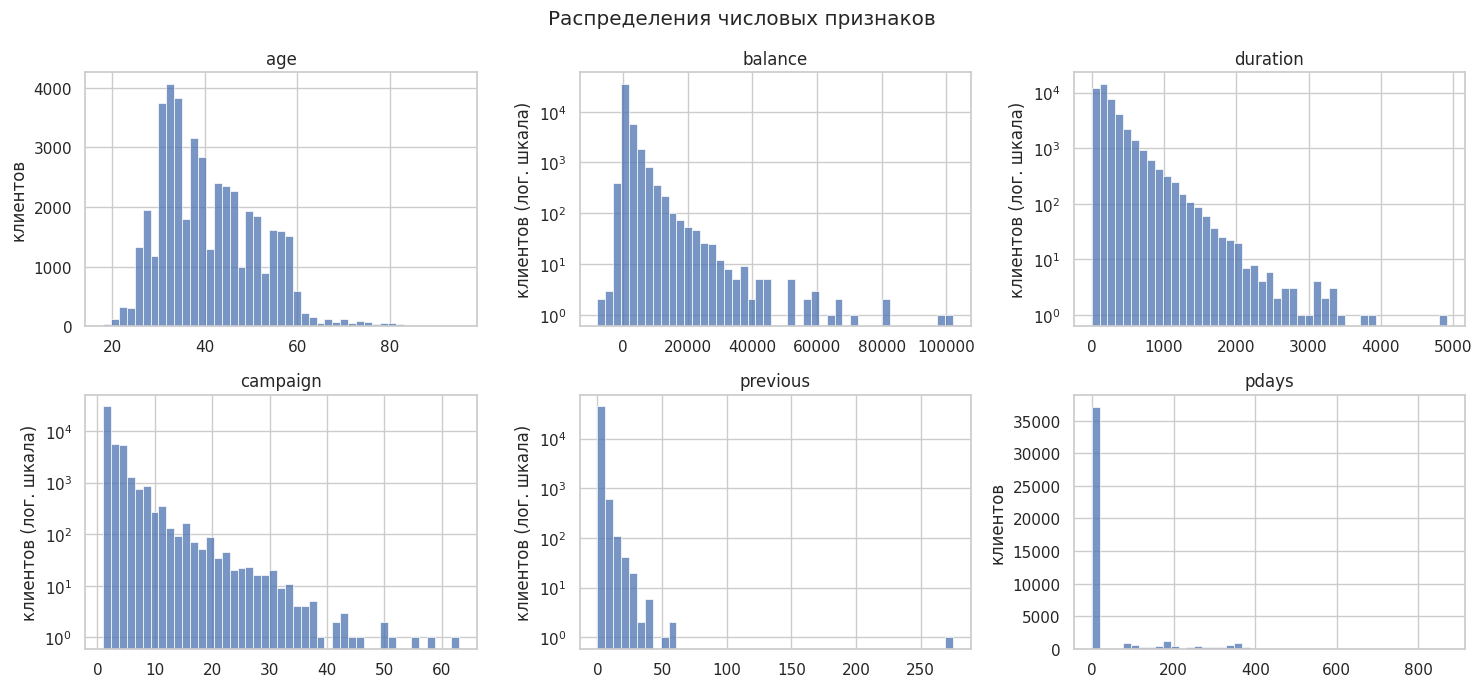

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), NUM_COLS):
    sns.histplot(data=df, x=col, bins=45, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    if col in ("balance", "duration", "campaign", "previous"):
        ax.set_yscale("log")
        ax.set_ylabel("клиентов (лог. шкала)")
    else:
        ax.set_ylabel("клиентов")
fig.suptitle("Распределения числовых признаков")
fig.tight_layout()

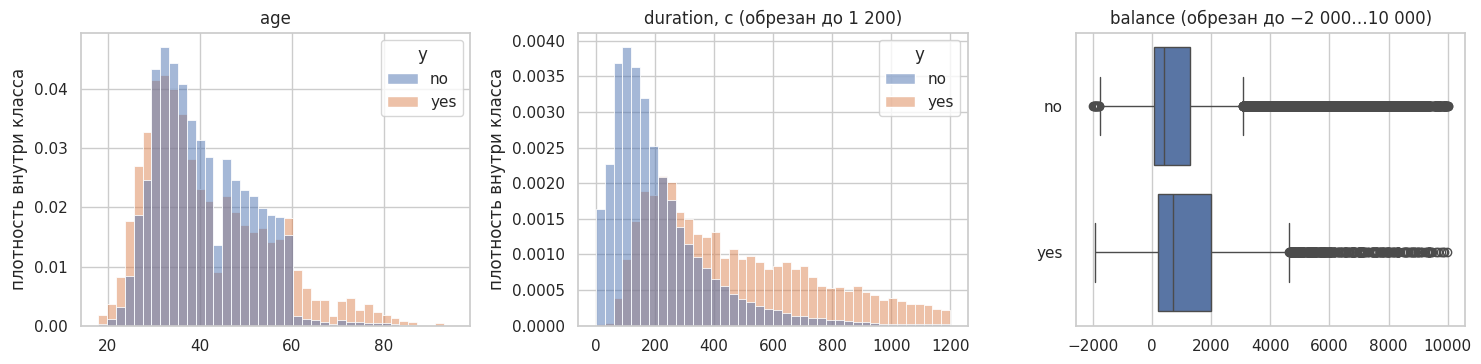

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (col, lim, title) in zip(axes[:2], [
    ("age", None, "age"),
    ("duration", (0, 1200), "duration, с (обрезан до 1 200)"),
]):
    data = df if lim is None else df[df[col].between(*lim)]
    sns.histplot(data=data, x=col, hue=TARGET, stat="density", common_norm=False, bins=40, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("плотность внутри класса")

sns.boxplot(data=df[df.balance.between(-2000, 10000)], x="balance", y=TARGET, ax=axes[2])
axes[2].set_title("balance (обрезан до −2 000…10 000)")
axes[2].set_xlabel("")
axes[2].set_ylabel("")
fig.tight_layout()

age распределён почти симметрично, слегка сдвинут вправо (медиана 39, 99-й перцентиль 71). Откликов больше среди молодых до 30 и пожилых после 65.

У balance тяжёлый правый хвост, медиана 448, максимум 102127, у 8.3% клиентов баланс отрицательный. Под линейные модели его надо масштабировать робастно (RobustScaler или логарифм), деревьям это не нужно.

duration связан с целью сильнее остальных (корреляция 0.39), медиана у откликнувшихся 426 секунд против 164 у остальных. Но признак с утечкой, к нему вернусь в разделе 6.

campaign убывает очень резко, медиана 2, 99-й перцентиль 16, максимум 63. Большинству звонят 1-3 раза, а при частых звонках отклик скорее падает.

pdays это смесь: 81.7% значений равны -1 (не контактировали), остальные размазаны до 871 дня.

Выбросов по правилу 1.5*IQR много у balance, duration, campaign и previous, но удалять их не стоит, это реальные редкие случаи.

## 5. Категориальные признаки

In [20]:
def conversion_table(col):
    work = df.assign(is_yes=df[TARGET].eq("yes"), value=df[col].fillna("unknown"))
    return (work.groupby("value")
                .agg(клиентов=("is_yes", "size"), конверсия=("is_yes", "mean"))
                .assign(**{"доля клиентов, %": lambda t: (t["клиентов"] / len(df) * 100).round(1),
                          "конверсия, %": lambda t: (t["конверсия"] * 100).round(1)})
                .drop(columns="конверсия")
                .sort_values("конверсия, %", ascending=False))

conversion_table("job")

,клиентов,"доля клиентов, %","конверсия, %"
value,,,
student,938,2.1,28.7
retired,2264,5.0,22.8
unemployed,1303,2.9,15.5
management,9458,20.9,13.8
admin.,5171,11.4,12.2
unknown,288,0.6,11.8
self-employed,1579,3.5,11.8
technician,7597,16.8,11.1
services,4154,9.2,8.9


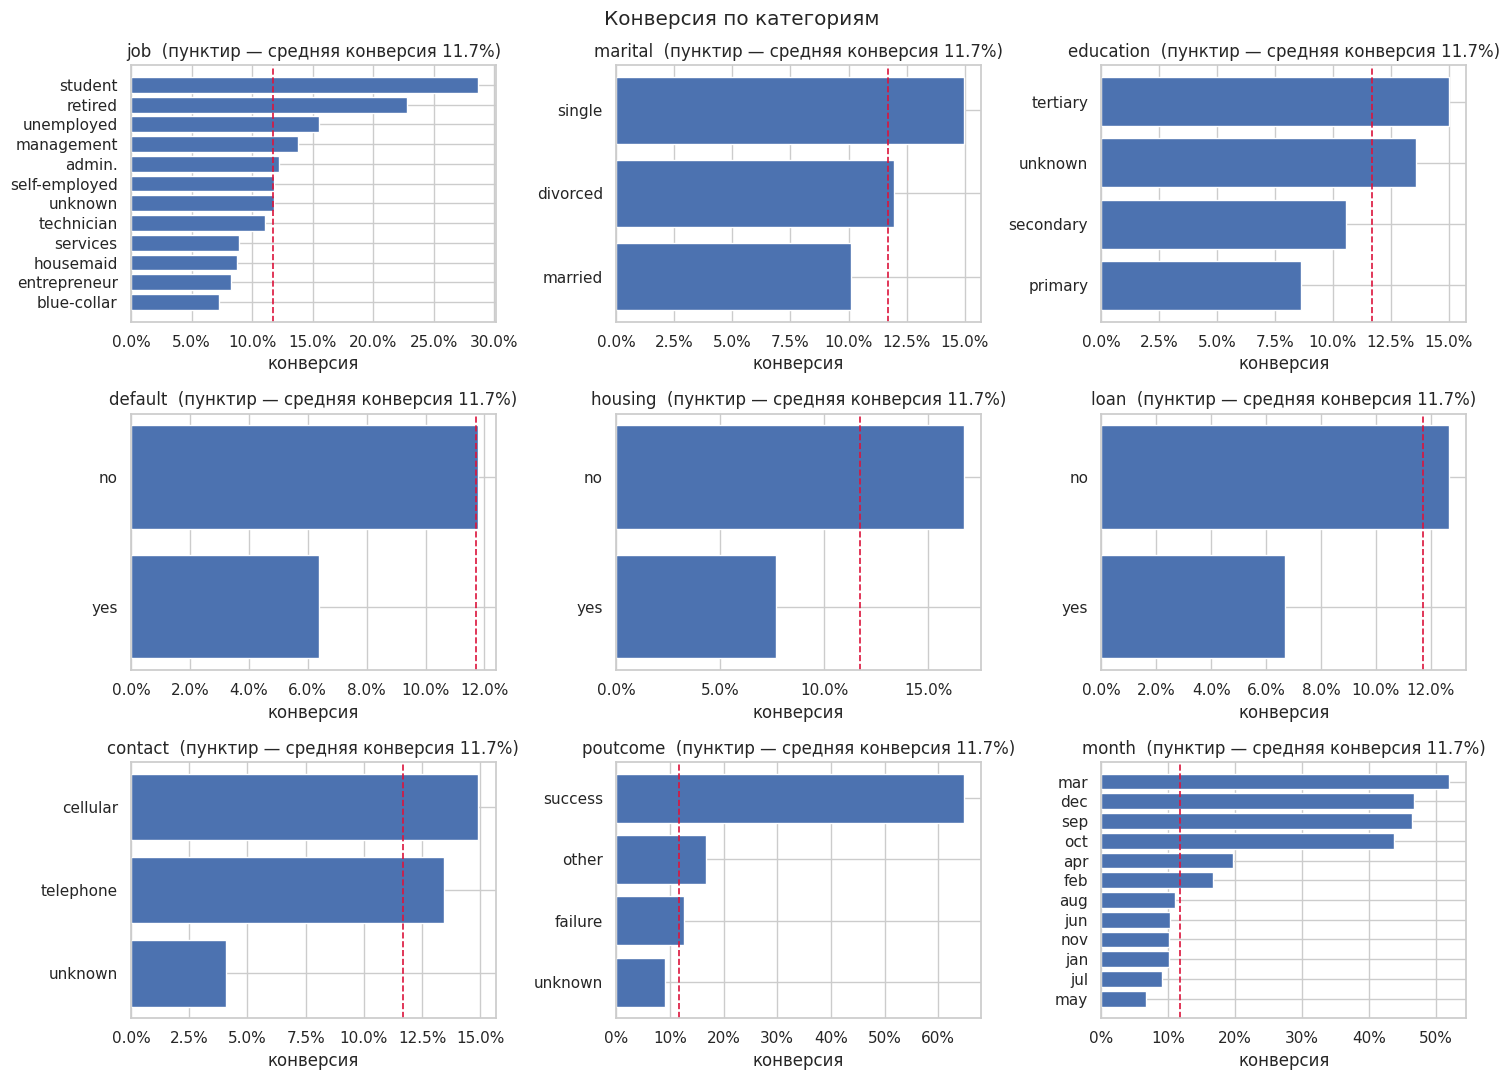

In [21]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.ravel(), CAT_COLS):
    rates = (df.assign(is_yes=df[TARGET].eq("yes"), value=df[col].fillna("unknown"))
               .groupby("value")["is_yes"].mean().sort_values())
    ax.barh(rates.index.astype(str), rates.values, color=sns.color_palette("deep")[0])
    ax.axvline(BASE_RATE, color="crimson", ls="--", lw=1.2)
    ax.set_title(f"{col}  (пунктир — средняя конверсия {BASE_RATE:.1%})")
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.set_xlabel("конверсия")
fig.suptitle("Конверсия по категориям")
fig.tight_layout()

In [22]:
pd.concat({c: conversion_table(c).head(4) for c in ["job", "education", "poutcome", "contact", "month"]}, names=["признак"])

клиентов  доля клиентов, %  конверсия, %
признак   value                                               
job       student          938               2.1          28.7
          retired         2264               5.0          22.8
          unemployed      1303               2.9          15.5
          management      9458              20.9          13.8
education tertiary       13301              29.4          15.0
          unknown         1857               4.1          13.6
          secondary      23202              51.3          10.6
          primary         6851              15.2           8.6
poutcome  success         1511               3.3          64.7
          other           1840               4.1          16.7
          failure         4901              10.8          12.6
          unknown        36959              81.7           9.2
contact   cellular       29285              64.8          14.9
          telephone       2906               6.4          13.4
          unknown        13020              28.8           4.1
month     mar              477               1.1          52.0
          dec              214               0.5          46.7
          sep              579               1.3          46.5
          oct              738               1.6          43.8

poutcome оказался самым сильным категориальным признаком: после успешной прошлой кампании конверсия 64.7%, а у тех, кого раньше не контактировали, 9.2%.

По job студенты (28.7%) и пенсионеры (22.8%) откликаются в 2-4 раза чаще blue-collar (7.3%) и entrepreneur (8.3%).

month сезонный и очень неровный: март 52.0%, декабрь 46.7%, сентябрь 46.5%, октябрь 43.8%, а май всего 6.7%. Только на удачные месяцы приходится 0.5-1.6% звонков, а на май 30.4% всех контактов. Похоже, месяц отражает график кампании, а не свойства клиента.

contact: cellular 14.9%, telephone 13.4%, без данных 4.1%, последнее скорее всего старые записи.

Если нет ипотеки или потребкредита, конверсия выше: 16.7% против 7.7% по housing и 12.7% против 6.7% по loan.

По education идёт tertiary 15.0%, secondary 10.6%, primary 8.6%, у marital single 14.9% против married 10.1%. default=yes всего 815 клиентов и конверсия ниже (6.4%), признак почти константный.

## 6. Потенциальные утечки и служебные признаки

In [23]:
never_contacted = df.pdays.eq(-1)
print(f"Без прошлых контактов: {never_contacted.mean():.1%}, конверсия {(df.loc[never_contacted, TARGET] == 'yes').mean():.2%}")
print(f"С прошлыми контактами: {(~never_contacted).mean():.1%}, конверсия {(df.loc[~never_contacted, TARGET] == 'yes').mean():.2%}")

duration_bins = pd.cut(df.duration, [0, 60, 180, 300, 600, np.inf],
                       labels=["≤ 1 мин", "1–3 мин", "3–5 мин", "5–10 мин", "> 10 мин"])
(df.assign(bucket=duration_bins)
   .groupby("bucket", observed=True)
   .agg(клиентов=(TARGET, "size"), конверсия=(TARGET, lambda s: (s == "yes").mean()))
   .assign(**{"доля клиентов, %": lambda t: (t["клиентов"] / len(df) * 100).round(1),
              "конверсия, %": lambda t: (t["конверсия"] * 100).round(1)})
   .drop(columns="конверсия"))

Без прошлых контактов: 81.7%, конверсия 9.16%
С прошлыми контактами: 18.3%, конверсия 23.07%


,клиентов,"доля клиентов, %","конверсия, %"
bucket,,,
≤ 1 мин,4763,10.5,0.2
1–3 мин,17894,39.6,3.9
3–5 мин,10277,22.7,10.9
5–10 мин,8484,18.8,19.2
> 10 мин,3790,8.4,48.4


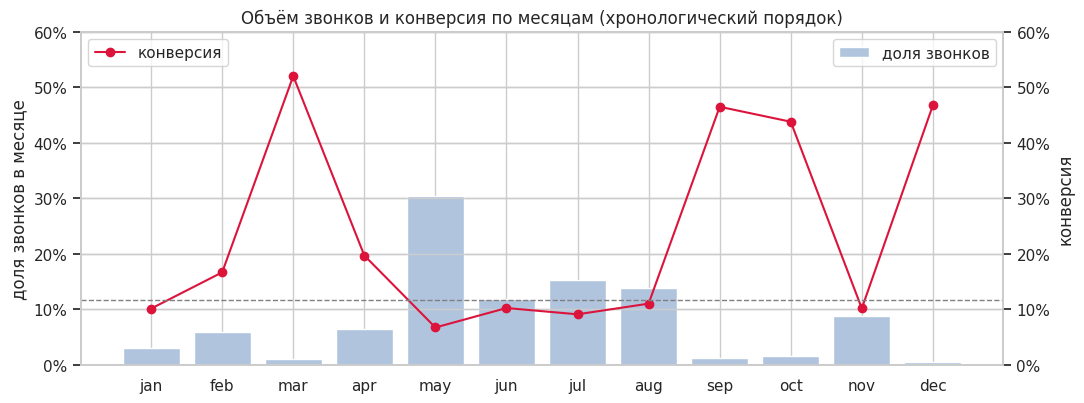

In [24]:
MONTH_ORDER = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_stats = (df.assign(is_yes=df[TARGET].eq("yes"))
                 .groupby("month")
                 .agg(клиентов=("is_yes", "size"), конверсия=("is_yes", "mean"))
                 .reindex(MONTH_ORDER)
                 .assign(доля=lambda t: t["клиентов"] / len(df)))

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(month_stats.index, month_stats["доля"], color="lightsteelblue", label="доля звонков")
ax.set_ylabel("доля звонков в месяце")
ax.set_ylim(0, 0.6)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax2 = ax.twinx()
ax2.plot(month_stats.index, month_stats["конверсия"], color="crimson", marker="o", label="конверсия")
ax2.axhline(BASE_RATE, color="gray", ls="--", lw=1)
ax2.set_ylabel("конверсия")
ax2.set_ylim(0, 0.6)
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_title("Объём звонков и конверсия по месяцам (хронологический порядок)")
ax.legend(loc="upper right")
ax2.legend(loc="upper left")
fig.tight_layout()

duration это утечка целевой переменной. Длительность звонка становится известна только после разговора, и она почти определяет результат: при длительности до минуты конверсия 0.2%, а больше 10 минут 48.4%. Метрики с ним получатся красивые, но в проде признака не будет, поэтому основную модель надо строить и проверять без него. Как вариант, оставить его только для приоритизации уже состоявшихся звонков.

month и day_of_week отражают график кампании, а не клиента. На тесте из другого периода будет сдвиг распределения, поэтому стоит сравнить модель с ними и без них.

poutcome, pdays и previous описывают прошлые кампании, у новых клиентов их просто нет (81.7% строк). Поэтому нужна категория unknown, иначе модель научится узнавать старых клиентов.

pdays и previous дублируют друг друга по смыслу, хватит одного.

## 7. Корреляции

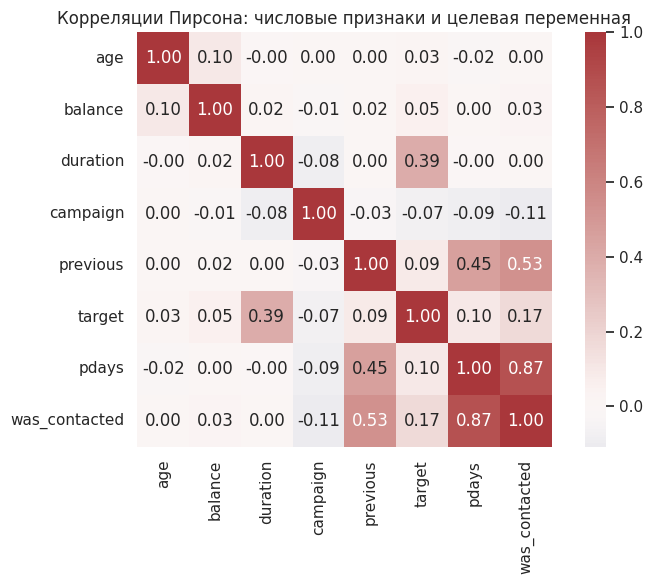

In [25]:
corr = (df[NUMERIC_COLS]
        .assign(target=df[TARGET].eq("yes").astype(int),
                pdays=df.pdays,
                was_contacted=df.pdays.ne(-1).astype(int))
        .corr())

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True, ax=ax)
ax.set_title("Корреляции Пирсона: числовые признаки и целевая переменная")
fig.tight_layout()

In [26]:
corr_target = (df[NUMERIC_COLS + ["pdays"]]
               .assign(target=df[TARGET].eq("yes").astype(int))
               .corr()["target"]
               .drop("target")
               .sort_values(key=abs, ascending=False))
corr_target.round(3).to_frame("корреляция с y")

,корреляция с y
duration,0.395
pdays,0.104
previous,0.093
campaign,-0.073
balance,0.053
age,0.025


Среди настоящих клиентских признаков мультиколлинеарности почти нет, самые сильные связи это previous с was_contacted (0.53) и pdays с previous (0.45). 0.87 между pdays и флагом was_contacted это одна и та же информация, поданная дважды, так что один из признаков лишний. Остальные числовые для линейных моделей можно оставить.

По силе линейной связи с целью идёт duration (0.395), потом pdays (0.104) и previous (0.093), дальше campaign (-0.073), balance (0.053) и age (0.025). Сами корреляции слабые, но категориальные признаки, особенно poutcome, несут гораздо больше сигнала, так что нужны деревья или бустинг, либо one-hot плюс логистическая регрессия.

## 8. Выводы и план подготовки данных

Данным: 45211 строк и 17 столбцов, полных дублей нет, классы 11.7% против 88.3%. Пропуски это исходные unknown: poutcome 81.7%, contact 28.8%, education 4.1%, job 0.6%. pdays == -1 совпадает с previous == 0 на всех 81.7% строк, а poutcome пустой ровно у тех, кого раньше не контактировали. day_of_week хранит день месяца.

Из признаков работают duration (но утечка), poutcome, month, contact, housing и loan, job (student, retired), education, balance, campaign. Пороги видно на графиках: duration больше 10 минут даёт 48.4% откликов, после примерно 5 звонков в кампании конверсия падает, без ипотеки и кредита она выше средней. Тяжёлые хвосты у balance, duration, campaign и previous.

План дальше:
1. unknown выношу в отдельную категорию, pdays делю на флаг "был контакт" и само значение, day_of_week проверяю и скорее всего убираю.
2. duration убираю из основной модели как утечку, но обучаю и вторую версию с ним, чтобы сравнить.
3. Кодирование: one-hot для номинальных, education и month пробую как ordinal, выбираю по валидации.
4. balance, duration и campaign масштабирую RobustScaler или StandardScaler, деревьям это не нужно.
5. Валидация через StratifiedKFold, метрики ROC-AUC, PR-AUC, F1 и recall по yes, с оглядкой на порядок по времени (month).
6. Иду от DummyClassifier к логистической регрессии, потом к бустингу (LightGBM или CatBoost), порог подбираю по PR-кривой.